# 📱 Mobile App Usage Analysis



In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv("mobile_app_usage_screen_time.csv")

In [ ]:
df.head()

,record_id,year,month,quarter,day_of_week,country,age_group,gender,device_brand,operating_system,...,app_rating_given,review_submitted,primary_usage_time,dark_mode_preference,location_permission,sleep_disruption_from_phone,screen_time_concern,mental_health_impact,digital_wellbeing_feature_used,app_deleted_and_reinstalled
0,APP0000001,2024,11,Q4,Thursday,Turkey,45-54,Male,Xiaomi,Android,...,4,No,Lunch (12-2pm),Sometimes,While Using,Moderate,Yes,Positive,Yes,Yes
1,APP0000002,2022,5,Q2,Friday,USA,25-34,Male,Huawei,Android,...,4,Yes,Evening (6-10pm),Sometimes,Never,NaN,Yes,Negative,Yes,Yes
2,APP0000003,2024,9,Q3,Sunday,USA,25-34,Male,Samsung,Android,...,4,Yes,Evening (6-10pm),Sometimes,While Using,NaN,No,Negative,No,Yes
3,APP0000004,2023,7,Q3,Tuesday,Pakistan,25-34,Male,Samsung,Android,...,4,No,Commute (9-11am),Never,Always,Moderate,Somewhat,Negative,Yes,No
4,APP0000005,2023,3,Q1,Tuesday,UAE,25-34,Male,OnePlus,Android,...,1,No,Commute (9-11am),Always,Not Applicable,Moderate,Yes,Neutral,Yes,No


In [ ]:
df.tail()

,record_id,year,month,quarter,day_of_week,country,age_group,gender,device_brand,operating_system,...,app_rating_given,review_submitted,primary_usage_time,dark_mode_preference,location_permission,sleep_disruption_from_phone,screen_time_concern,mental_health_impact,digital_wellbeing_feature_used,app_deleted_and_reinstalled
9995,APP0009996,2022,6,Q2,Sunday,Indonesia,25-34,Female,Apple,iOS,...,3,No,Lunch (12-2pm),Sometimes,While Using,Moderate,Yes,Neutral,No,Yes
9996,APP0009997,2022,8,Q3,Saturday,USA,18-24,Male,Apple,iOS,...,5,No,Lunch (12-2pm),Sometimes,Not Applicable,Mild,Somewhat,Negative,No,Yes
9997,APP0009998,2024,3,Q1,Tuesday,USA,45-54,Prefer not to say,Xiaomi,Android,...,5,No,Afternoon (2-6pm),Never,Never,NaN,Yes,Positive,No,Yes
9998,APP0009999,2022,12,Q4,Friday,Japan,55-64,Female,Xiaomi,Android,...,5,No,Late Night (10pm+),Never,Never,Mild,Somewhat,Neutral,No,Yes
9999,APP0010000,2022,1,Q1,Sunday,India,13-17,Prefer not to say,Vivo,Android,...,3,No,Evening (6-10pm),Always,While Using,NaN,Yes,Negative,No,No


In [ ]:
df.shape

(10000, 34)

In [ ]:
df.columns

Index(['record_id', 'year', 'month', 'quarter', 'day_of_week', 'country',
       'age_group', 'gender', 'device_brand', 'operating_system',
       'network_connection', 'app_category', 'app_name', 'subscription_type',
       'daily_screen_time_minutes', 'session_duration_minutes',
       'sessions_per_day', 'app_opens_per_day', 'data_used_mb_per_day',
       'battery_drain_pct_per_session', 'notifications_received_per_day',
       'notification_settings', 'in_app_purchase', 'monthly_spend_usd',
       'app_rating_given', 'review_submitted', 'primary_usage_time',
       'dark_mode_preference', 'location_permission',
       'sleep_disruption_from_phone', 'screen_time_concern',
       'mental_health_impact', 'digital_wellbeing_feature_used',
       'app_deleted_and_reinstalled'],
      dtype='str')

**Part 2: Understanding**

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 34 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   record_id                       10000 non-null  str    
 1   year                            10000 non-null  int64  
 2   month                           10000 non-null  int64  
 3   quarter                         10000 non-null  str    
 4   day_of_week                     10000 non-null  str    
 5   country                         10000 non-null  str    
 6   age_group                       10000 non-null  str    
 7   gender                          10000 non-null  str    
 8   device_brand                    10000 non-null  str    
 9   operating_system                10000 non-null  str    
 10  network_connection              10000 non-null  str    
 11  app_category                    10000 non-null  str    
 12  app_name                        10000 non-nu

In [ ]:
df["gender"].value_counts()

gender
Male                 4875
Female               4612
Prefer not to say     513
Name: count, dtype: int64

In [ ]:
df["country"].value_counts()

country
USA            1257
India          1170
UK              826
Pakistan        819
Brazil          698
Germany         673
Canada          644
UAE             624
Indonesia       618
Nigeria         493
Australia       489
France          489
South Korea     428
Japan           403
Turkey          369
Name: count, dtype: int64

In [ ]:
df["age_group"].value_counts()

age_group
25-34    2795
18-24    2463
35-44    1993
45-54    1017
13-17     986
55-64     526
65+       220
Name: count, dtype: int64

In [ ]:
df["daily_screen_time_minutes"].describe()      #وقت الشاشة بالدقايق (وبالساعات!)

count    10000.000000
mean        85.500640
std         70.969522
min          5.700000
25%         35.500000
50%         63.400000
75%        112.700000
max        600.000000
Name: daily_screen_time_minutes, dtype: float64

In [ ]:
df["notifications_received_per_day"].describe()          # الاشعارات#

count    10000.000000
mean        25.006400
std          5.056057
min          9.000000
25%         21.000000
50%         25.000000
75%         28.000000
max         49.000000
Name: notifications_received_per_day, dtype: float64

In [ ]:
df["gender"] == "Male"

0        True
1        True
2        True
3        True
4        True
        ...  
9995    False
9996     True
9997    False
9998    False
9999    False
Name: gender, Length: 10000, dtype: bool

**Part 3: Cleaning**

In [ ]:
df.isnull().sum()

record_id                            0
year                                 0
month                                0
quarter                              0
day_of_week                          0
country                              0
age_group                            0
gender                               0
device_brand                         0
operating_system                     0
network_connection                   0
app_category                         0
app_name                             0
subscription_type                    0
daily_screen_time_minutes            0
session_duration_minutes             0
sessions_per_day                     0
app_opens_per_day                    0
data_used_mb_per_day                 0
battery_drain_pct_per_session        0
notifications_received_per_day       0
notification_settings                0
in_app_purchase                      0
monthly_spend_usd                    0
app_rating_given                     0
review_submitted         

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["gender"].unique()

<StringArray>
['Male', 'Female', 'Prefer not to say']
Length: 3, dtype: str

In [ ]:
df["daily_screen_time_minutes"].describe()

count    10000.000000
mean        85.500640
std         70.969522
min          5.700000
25%         35.500000
50%         63.400000
75%        112.700000
max        600.000000
Name: daily_screen_time_minutes, dtype: float64

**Part 4: Questions & Answers**

 **🎯 أسئلة المشروع
 
مين أكتر إشعارات بيستلمو: الشباب ولا البنات؟
 

In [ ]:
print(round(df[df["gender"] == "Male"]["notifications_received_per_day"].mean(), 2))
print(round(df[df["gender"] == "Female"]["notifications_received_per_day"].mean(), 2))

24.97
25.02


الذكور 25.02 , الإناث 24.97 : الفرق ضئيل جداً (0.05 فقط) — لا يوجد فرق جوهري بين الجنسين!

<Axes: title={'center': 'Average Notifications by Gender'}, xlabel='gender'>

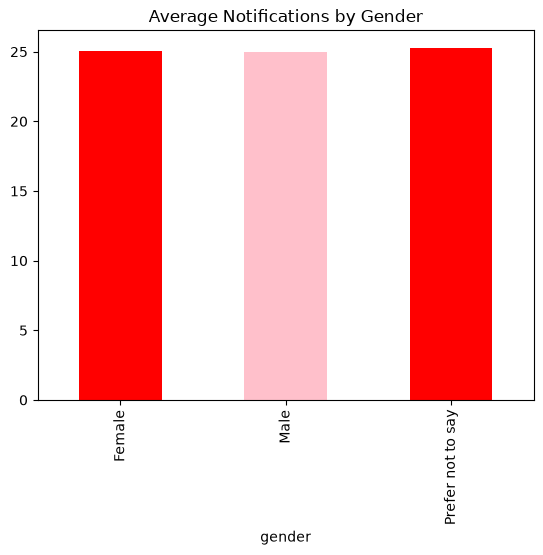

In [ ]:
df.groupby("gender")["notifications_received_per_day"].mean().plot(
    kind="bar",
    color=["red", "pink"],
    title="Average Notifications by Gender"
)


السؤال 2: هل تأثير الموبايل عالصحة النفسية بيفرق بين الشباب والبنات؟

In [ ]:
df[df["gender"] == "Male"]["mental_health_impact"].value_counts(normalize=True) 


mental_health_impact
Neutral          0.343795
Negative         0.246359
Positive         0.225436
Very Negative    0.109538
Very Positive    0.074872
Name: proportion, dtype: float64

In [ ]:
df[df["gender"] == "Female"]["mental_health_impact"].value_counts(normalize=True)

mental_health_impact
Neutral          0.349957
Negative         0.242845
Positive         0.221596
Very Negative    0.102559
Very Positive    0.083044
Name: proportion, dtype: float64

النسب متقاربة جداً بين الجنسين — لا يوجد فرق جوهري

<Axes: title={'center': 'Mental Health Impact Distribution'}>

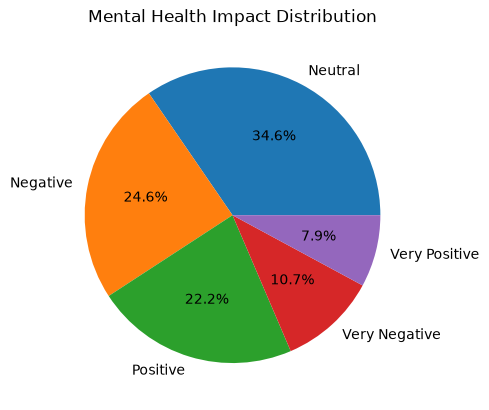

In [ ]:
df["mental_health_impact"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    title="Mental Health Impact Distribution"
)

السؤال 3: مين أكتر دولة بتقعد عالموبايل؟

In [ ]:
df.groupby("country")["daily_screen_time_minutes"].mean().sort_values(ascending=False)

country
France         93.499387
Canada         90.580745
Brazil         86.954155
Japan          86.888337
USA            86.411297
UK             86.217676
UAE            85.053526
India          84.969145
Indonesia      83.906958
Pakistan       83.651404
Australia      83.078732
South Korea    82.996028
Turkey         82.823035
Germany        82.524666
Nigeria        81.755578
Name: daily_screen_time_minutes, dtype: float64

فرنسا هي المركز الاول 

<Axes: title={'center': 'Screen Time by Country (Ranked)'}, xlabel='country'>

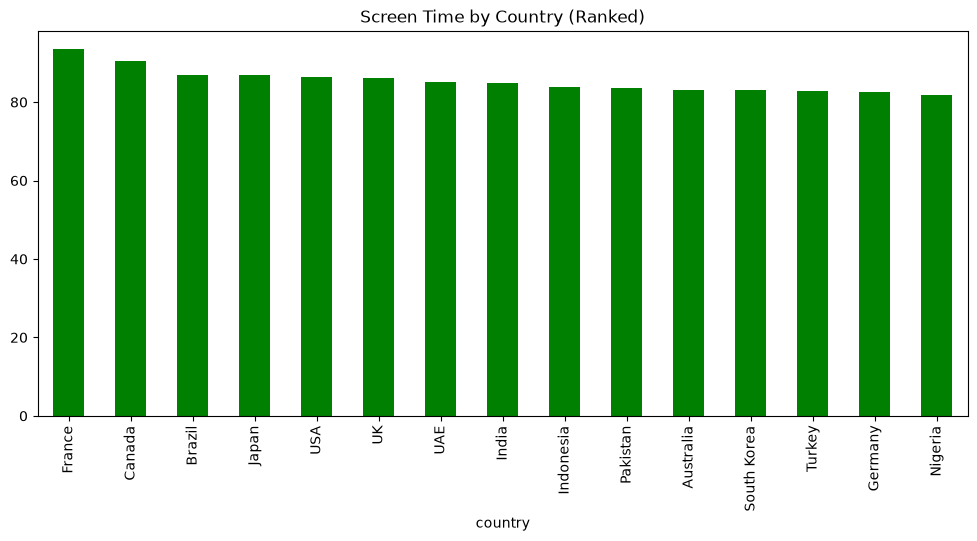

In [2]:
df.groupby("country")["daily_screen_time_minutes"].mean().sort_values(ascending=False).plot(
    kind="bar",
    color="green",
    title="Screen Time by Country (Ranked)",
    figsize=(12, 5)
)

Part 5: Python Core Skills — Advanced Processing

In [3]:
# استخراج أول 20 سجل كقائمة قواميس
first20 = df.head(20)
user_list = first20.to_dict(orient="records")

# 1) map + lambda: تحويل وقت الشاشة لساعات
screen_time_hour = list(map(lambda user: round(user["daily_screen_time_minutes"] / 60, 2), user_list))
print("وقت الشاشة بالساعات (أول 5):", screen_time_hour[:5])

# 2) filter: المستخدمين ذوي الاستخدام المرتفع (>60 دقيقة)
high_screen_time_user = list(filter(lambda user: user["daily_screen_time_minutes"] > 60, user_list))
print("عدد المستخدمين عالي الاستخدام:", len(high_screen_time_user))

وقت الشاشة بالساعات (أول 5): [1.27, 1.37, 0.26, 1.04, 1.49]
عدد المستخدمين عالي الاستخدام: 11


Part 6: OOP — Classes & Inheritance

In [4]:
class Users:

  def __init__(
      self,
      record_id, year, month, quarter, day_of_week, country,
      age_group, gender, device_brand, operating_system,
      network_connection, app_category, app_name, subscription_type,
      daily_screen_time_minutes, session_duration_minutes,
      sessions_per_day, app_opens_per_day, data_used_mb_per_day,
      battery_drain_pct_per_session, notifications_received_per_day,
      notification_settings, in_app_purchase, monthly_spend_usd,
      app_rating_given, review_submitted, primary_usage_time,
      dark_mode_preference, location_permission,
      sleep_disruption_from_phone, screen_time_concern,
      mental_health_impact, digital_wellbeing_feature_used,
      app_deleted_and_reinstalled,
  ):
    self.record_id = record_id
    self.year = year
    self.month = month
    self.quarter = quarter
    self.day_of_week = day_of_week
    self.country = country
    self.age_group = age_group
    self.gender = gender
    self.device_brand = device_brand
    self.operating_system = operating_system
    self.network_connection = network_connection
    self.app_category = app_category
    self.app_name = app_name
    self.subscription_type = subscription_type
    self.daily_screen_time_minutes = daily_screen_time_minutes
    self.session_duration_minutes = session_duration_minutes
    self.sessions_per_day = sessions_per_day
    self.app_opens_per_day = app_opens_per_day
    self.data_used_mb_per_day = data_used_mb_per_day
    self.battery_drain_pct_per_session = battery_drain_pct_per_session
    self.notifications_received_per_day = notifications_received_per_day
    self.notification_settings = notification_settings
    self.in_app_purchase = in_app_purchase
    self.monthly_spend_usd = monthly_spend_usd
    self.app_rating_given = app_rating_given
    self.review_submitted = review_submitted
    self.primary_usage_time = primary_usage_time
    self.dark_mode_preference = dark_mode_preference
    self.location_permission = location_permission
    self.sleep_disruption_from_phone = sleep_disruption_from_phone
    self.screen_time_concern = screen_time_concern
    self.mental_health_impact = mental_health_impact
    self.digital_wellbeing_feature_used = digital_wellbeing_feature_used
    self.app_deleted_and_reinstalled = app_deleted_and_reinstalled

  def display_info(self):
    print(
        f"record_id: {self.record_id} | year: {self.year} | gender:"
        f" {self.gender} | country: {self.country}"
    )

  def user_summary(self):
    return (
        f"Record ID: {self.record_id} | App: {self.app_name} | Screen Time:"
        f" {self.daily_screen_time_minutes}m | Plan: {self.subscription_type}"
    )


class FreeUser(Users):

  def __init__(self, **data):
    super().__init__(**data)
    self.ads = True

  def check_user_plan(self):
    return f"User {self.record_id} is on the Free tier using {self.app_name}."


class PaidUser(Users):

  def __init__(self, **data):
    super().__init__(**data)
    self.ads = False

  def check_user_plan(self):
    return (
        f"User {self.record_id} is on Premium Paid tier using {self.app_name}."
    )


# إنشاء الكائنات حسب نوع الاشتراك
users = []
for index, row in df.head(20).iterrows():
  if row["subscription_type"] == "Free":
    current_user = FreeUser(**row.to_dict())
  else:
    current_user = PaidUser(**row.to_dict())
  users.append(current_user)

print(f"{len(users)} users objects created successfully.\n")

# اختبار أول مستخدم
first_user = users[0]
print("First User Test:")
print("-" * 17)
print(first_user.check_user_plan())
print(f"Has Ads: {first_user.ads}")
print(first_user.user_summary())
first_user.display_info()

20 users objects created successfully.

First User Test:
-----------------
User APP0000001 is on Premium Paid tier using Snapchat.
Has Ads: False
Record ID: APP0000001 | App: Snapchat | Screen Time: 76.4m | Plan: Paid Yearly
record_id: APP0000001 | year: 2024 | gender: Male | country: Turkey


Part 7: Exception Handling

In [5]:
class InvalidDataError(Exception):
  def __init__(self, message):
    super().__init__(message)


def check_rating(rating):
  try:
    if rating < 1 or rating > 5:
      raise InvalidDataError(
          "Invalid rating value. Rating must be between 1 and 5"
      )
    else:
      return "Valid rating"
  except InvalidDataError as e:
    print("Error caught:", e)


# اختبار الدالة
print(check_rating(4))
print(check_rating(7))

Valid rating
Error caught: Invalid rating value. Rating must be between 1 and 5
None


Part 8: NumPy — Advanced Statistics

In [8]:
screen_time_arr = np.array(df["daily_screen_time_minutes"])
session_duration_arr = np.array(df["session_duration_minutes"])

screen_time_hours = screen_time_arr / 60
high_screen_time = screen_time_arr[screen_time_arr > 100]

print("Mean Screen Time:", screen_time_arr.mean())
print("Max Screen Time:", screen_time_arr.max())
print("Min Screen Time:", screen_time_arr.min())

Mean Screen Time: 85.50064
Max Screen Time: 600.0
Min Screen Time: 5.7


# 🔚 الختام والنتائج

# 
وهيك بنكون خلصناا مشروع الموبايل وعملنا 3 اسئله

 انا بحد ذاتي كنت متوقعه نتائج تانيه مثلا مين بقعد ع موبايل اكتر توقعت تكون تركيا ولكن طلعت فرنسا

 
 مين أكتر إشعارات؟   تعادل 

  الصحة النفسية بين الجنسين؟ متقاربه 
  
  وهيك احنا بنتعلم انو لو احنا اعتمدنا التوقعات لكان كل شي خرب لهيك انوجدت الداتا 

الفريق 🤝:

أبرار محمد حرارة — التحليل والأسئلة والرسمات (Part 1-4)

سندس محمد السطري  — البرمجة الشيئية والاستثناءات (Part 5-8)

هندسة علم البيانات والذكاء الاصطناعي